In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import time

from sklearn.utils import shuffle
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import RFECV
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_val_score
from sklearn import metrics, preprocessing
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

from sklearn.metrics import confusion_matrix, classification_report, cohen_kappa_score, make_scorer
from sklearn.impute import KNNImputer
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.under_sampling import TomekLinks
from imblearn.over_sampling import SMOTE
from sklearn.calibration import calibration_curve
from sklearn.pipeline import Pipeline

import shap
import lime
import lime.lime_tabular

In [2]:
df_train = pd.read_csv('./ILD_df_train_impute.csv')
df_test = pd.read_csv('./ILD_df_test_impute.csv')

print(df_train.shape)
print(df_test.shape)

(1412, 546)
(250, 546)


In [3]:
COL_NAME = df_train.columns.tolist()
COL_NAME.remove('C_ID')
COL_NAME.remove('Outcome')
COL_NAME.append('Outcome')

df_train = df_train[COL_NAME]
print(df_train.shape)

for i in np.arange(0, df_train.shape[1]-1):
    if df_train.iloc[:, i].isnull().sum() > 0:
        print(i)

Numeric_col = ['Age','BMI','PC1','PC2','PC3','PC4','PC5','PRS']

Num_scaler = MinMaxScaler()        #  = (value-min)/(max-min)
df_train[Numeric_col] = Num_scaler.fit_transform(df_train[Numeric_col])

Binary_col = ['Male','smoke','Outcome']

for j in range(df_train.shape[1]):
    if df_train.columns[j] in Binary_col:
        df_train[df_train.columns[j]] = df_train[df_train.columns[j]].astype(int)


df_train = shuffle(df_train, random_state=629).reset_index(drop=True)
df_train.head()

(1412, 545)


,Male,Age,smoke,BMI,PC1,PC2,PC3,PC4,PC5,Affx_10309818,...,rs9833888,rs9837602,rs986877,rs9888758,rs9888871,rs9897447,rs9953269,rs9965930,PRS,Outcome
0,0,0.332859,0,0.368732,0.869420,0.549902,0.411762,0.173180,0.393477,0.0,...,0.000000,0.000000,0.0,0.000000,0.383914,0.000000,-0.386651,-0.386521,0.095649,0
1,1,0.612498,1,0.251810,0.809504,0.531056,0.573928,0.300595,0.464284,0.0,...,0.000000,0.000000,0.0,0.325702,0.000000,-0.499763,-0.386651,-0.386521,0.303381,0
2,0,0.412897,0,0.189059,0.779856,0.549324,0.412285,0.319398,0.676067,0.0,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.643461,1
3,0,0.638589,0,0.269241,0.826125,0.529446,0.351991,0.152288,0.311946,0.0,...,0.000000,0.000000,0.0,0.325702,0.383914,0.000000,0.000000,0.000000,0.542569,1
4,0,0.662916,0,0.425583,0.923478,0.498387,0.508072,0.184316,0.631259,0.0,...,-0.757756,-0.757756,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.314145,0


In [4]:
df_test = df_test[COL_NAME]
print(df_test.shape)

for i in np.arange(0, df_test.shape[1]-1):
    if df_test.iloc[:, i].isnull().sum() > 0:
        print(i)

df_test[Numeric_col] = Num_scaler.transform(df_test[Numeric_col])

for j in range(df_test.shape[1]):
    if df_test.columns[j] in Binary_col:
        df_test[df_test.columns[j]] = df_test[df_test.columns[j]].astype(int)


df_test = shuffle(df_test, random_state=629).reset_index(drop=True)
df_test.head()

(250, 545)


,Male,Age,smoke,BMI,PC1,PC2,PC3,PC4,PC5,Affx_10309818,...,rs9833888,rs9837602,rs986877,rs9888758,rs9888871,rs9897447,rs9953269,rs9965930,PRS,Outcome
0,0,0.582600,0,0.367123,0.874519,0.552593,0.532102,0.223201,0.420355,-0.429917,...,0.000000,0.000000,0.0,0.000000,0.0,0.0,-0.386651,-0.386521,0.572557,1
1,0,0.371207,0,0.388308,0.639109,0.596367,0.454100,0.218315,0.519533,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.524610,1
2,1,0.362571,0,0.311075,0.857061,0.563650,0.417047,0.207397,0.502916,0.000000,...,-0.378878,-0.378878,0.0,0.325702,0.0,0.0,0.000000,0.000000,0.471660,1
3,1,0.288971,0,0.348351,0.853155,0.533206,0.562524,0.220698,0.508960,-0.429917,...,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.659951,1
4,0,0.734939,0,0.242156,0.798735,0.537199,0.551713,0.226267,0.423156,0.000000,...,0.000000,0.000000,0.0,0.325702,0.0,0.0,0.000000,0.000000,0.732009,1


In [5]:
###---------- X, Y dataset  ----------###
X_train = df_train.iloc[:,:-1]
Y_train = df_train.iloc[:,-1]

X_test = df_test.iloc[:,:-1]
Y_test = df_test.iloc[:,-1]


print(Y_train.value_counts())


print(X_train.shape)
print(Y_train.shape)
print('-----------')
print(X_test.shape)
print(Y_test.shape)

Outcome
0    706
1    706
Name: count, dtype: int64
(1412, 544)
(1412,)
-----------
(250, 544)
(250,)


## Logistic Regression

In [6]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = LogisticRegression(C=0.005,class_weight=None,l1_ratio=1,solver='liblinear',random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

Accuracy = 0.74
Precision = 0.9286
Recall = 0.52
F1 = 0.6667
AUC = 0.74


In [7]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = LogisticRegression(C=0.005,class_weight=None,l1_ratio=1,solver='liblinear',random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_LR.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_LR.csv', index=False)

AUC = 0.74


In [8]:
starttime = time.time()
#########################

best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(C=0.005,class_weight=None,l1_ratio=1,solver='liblinear',random_state=0))
])
best_model.fit(X_train, Y_train)

Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)

n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []

mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):
    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    
    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))

    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')

metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")

orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)

orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)

roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,              
    'tpr_lower': tpr_lower, 
    'tpr_upper': tpr_upper, 
    'model': 'LR',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})

roc_ci_df.to_csv("./roc_bootstrap_ci_LR.csv", index=False)

Bootstrap completed in 9.104 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.792 (0.744, 0.840)
95% CI of Precision           : 0.835 (0.757, 0.899)
95% CI of Sensitivity (Recall): 0.728 (0.650, 0.802)
95% CI of F1-Score            : 0.778 (0.718, 0.833)
95% CI of AUROC               : 0.855 (0.805, 0.902)


## Random Forest model

In [9]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = RandomForestClassifier(n_estimators=700, criterion='gini',max_depth=25,min_samples_leaf=1,
                                 min_samples_split=15,max_features='sqrt', class_weight=None, random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

Accuracy = 0.8
Precision = 0.8099
Recall = 0.784
F1 = 0.7967
AUC = 0.8855


In [10]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = RandomForestClassifier(n_estimators=700, criterion='gini',max_depth=25,min_samples_leaf=1,
                                 min_samples_split=15,max_features='sqrt', class_weight=None, random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_RF.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_RF.csv', index=False)

AUC = 0.8855


In [11]:
starttime = time.time()
#########################


best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(n_estimators=700, criterion='gini',max_depth=25,min_samples_leaf=1,
                                 min_samples_split=15,max_features='sqrt', class_weight=None, random_state=0))
])
best_model.fit(X_train, Y_train)


Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)


n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []


mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):

    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    

    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))


    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0  
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')


metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")

orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)


orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)


roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,          
    'tpr_lower': tpr_lower,     
    'tpr_upper': tpr_upper,   
    'model': 'RF',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})


roc_ci_df.to_csv("./roc_bootstrap_ci_RF.csv", index=False)

Bootstrap completed in 10.515 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.800 (0.748, 0.848)
95% CI of Precision           : 0.810 (0.733, 0.878)
95% CI of Sensitivity (Recall): 0.784 (0.708, 0.856)
95% CI of F1-Score            : 0.797 (0.738, 0.849)
95% CI of AUROC               : 0.886 (0.839, 0.926)


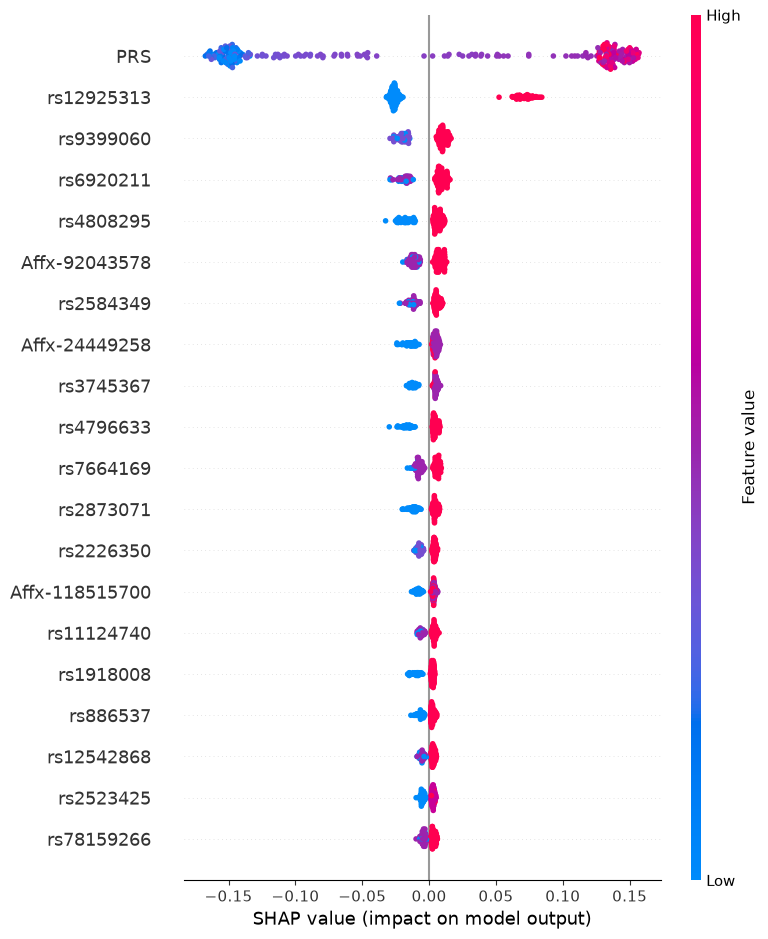

In [6]:
###---------- SHAP Values (Shapley additive explanations) ----------###
Target_df = X_test ; Target_outcome = Y_test
COL_NAME_SHAP = Target_df.columns.tolist()
COL_NAME_SHAP = [x.replace('Affx_', 'Affx-') if x.startswith('Affx_') else x for x in COL_NAME_SHAP]

MLmodel = RandomForestClassifier(n_estimators=700, criterion='gini',max_depth=25,min_samples_leaf=1,
                                 min_samples_split=15,max_features='sqrt', class_weight=None, random_state=0)
MLmodel.fit(X_train, Y_train)
shap_values = shap.TreeExplainer(MLmodel).shap_values(Target_df)[:, :, 1]
shap.summary_plot(shap_values, Target_df, max_display=20, feature_names=COL_NAME_SHAP, show=False)

plt.savefig('SHAP_values_ILD_GWAS_RF.tif', dpi=300, bbox_inches='tight', pad_inches=0)   # tiff   jpg   png

PRS               0.287505
rs12925313        0.055250
rs9399060         0.015158
rs6920211         0.013579
rs4808295         0.010399
Affx_92043578     0.009387
rs4796633         0.008289
rs2584349         0.007804
Affx_24449258     0.007595
rs2873071         0.006936
rs3745367         0.006716
rs7664169         0.006196
BMI               0.005201
rs2226350         0.004776
Affx_118515700    0.004692
PC4               0.004625
Age               0.004574
rs11124740        0.004502
PC3               0.004471
PC2               0.004466
PC5               0.004364
PC1               0.004263
rs1918008         0.004152
rs12542868        0.004150
rs886537          0.003971
rs117185387       0.003913
rs680500          0.003898
rs2523425         0.003693
rs78159266        0.003649
rs35068797        0.003526
dtype: float64


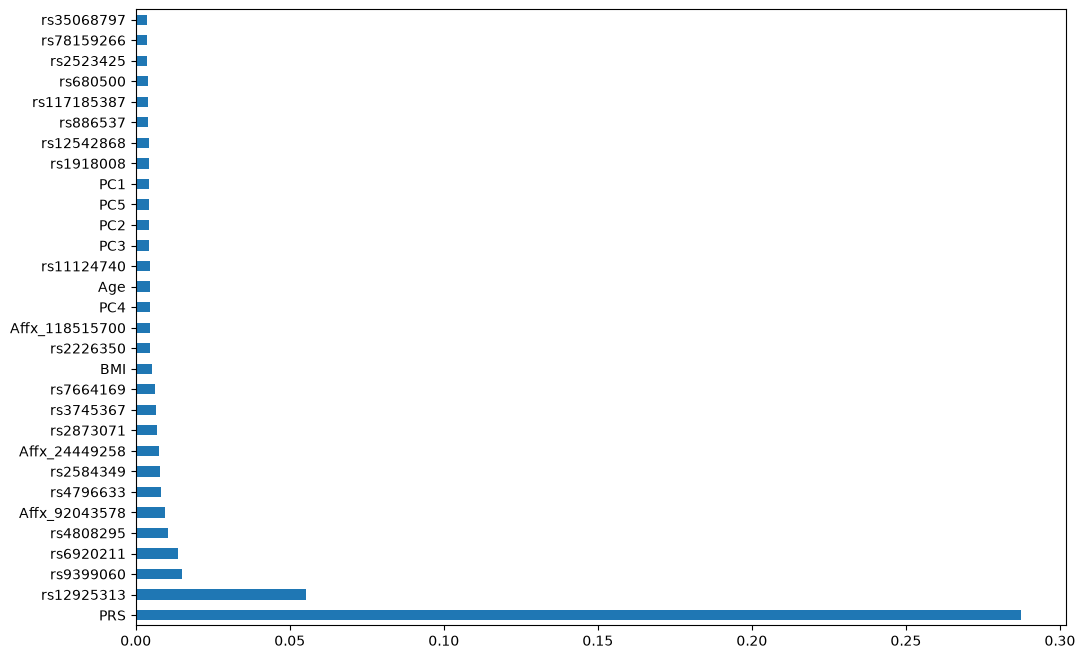

In [8]:
###---------- Feature Importances ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = RandomForestClassifier(n_estimators=700, criterion='gini',max_depth=25,min_samples_leaf=1,
                                 min_samples_split=15,max_features='sqrt', class_weight=None, random_state=0)
MLmodel.fit(X_train, Y_train)

plt.rcParams['figure.figsize'] = [12, 8]
ax = pd.Series(MLmodel.feature_importances_, index=Target_df.columns).nlargest(30).plot(kind='barh')
fig = ax.get_figure()

print(pd.Series(MLmodel.feature_importances_, index=Target_df.columns).nlargest(30))
pd.Series(MLmodel.feature_importances_, index=Target_df.columns).nlargest(30).round(4).to_csv('Top20_SNPs_feature_importances_RF.csv')

## SVM

In [12]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = SVC(C=5,gamma=0.005,kernel='rbf',class_weight=None,probability=True,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy = 0.764
Precision = 0.75
Recall = 0.792
F1 = 0.7704
AUC = 0.851


In [13]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = SVC(C=5,gamma=0.005,kernel='rbf',class_weight=None,probability=True,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_SVM.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_SVM.csv', index=False)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


AUC = 0.851


In [14]:
starttime = time.time()
#########################


best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(C=5,gamma=0.005,kernel='rbf',class_weight=None,probability=True,random_state=0))
])
best_model.fit(X_train, Y_train)

Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)


n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []


mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):

    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    

    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))


    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0 
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')


metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")

orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)


orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)


roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,      
    'tpr_lower': tpr_lower,  
    'tpr_upper': tpr_upper,   
    'model': 'SVM',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})


roc_ci_df.to_csv("./roc_bootstrap_ci_SVM.csv", index=False)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Bootstrap completed in 11.392 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.744 (0.688, 0.800)
95% CI of Precision           : 0.740 (0.660, 0.815)
95% CI of Sensitivity (Recall): 0.752 (0.676, 0.832)
95% CI of F1-Score            : 0.746 (0.683, 0.805)
95% CI of AUROC               : 0.811 (0.756, 0.865)


## LGBM

In [15]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = LGBMClassifier(boosting_type='gbdt',learning_rate=0.15,n_estimators=100,num_leaves=7,
                         max_depth=7,class_weight='balanced',min_child_samples=10,
                         colsample_bytree=0.6,subsample=0.8,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

[LightGBM] [Info] Number of positive: 706, number of negative: 706
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.015755 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3521
[LightGBM] [Info] Number of data points in the train set: 1412, number of used features: 544
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Accuracy = 0.776
Precision = 0.7717
Recall = 0.784
F1 = 0.7778
AUC = 0.8647


In [16]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = LGBMClassifier(boosting_type='gbdt',learning_rate=0.15,n_estimators=100,num_leaves=7,
                         max_depth=7,class_weight='balanced',min_child_samples=10,
                         colsample_bytree=0.6,subsample=0.8,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_LGBM.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))


prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_LGBM.csv', index=False)

[LightGBM] [Info] Number of positive: 706, number of negative: 706
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017845 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3521
[LightGBM] [Info] Number of data points in the train set: 1412, number of used features: 544
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
AUC = 0.8647


In [17]:
starttime = time.time()
#########################


best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lgbm', LGBMClassifier(boosting_type='gbdt',learning_rate=0.15,n_estimators=100,num_leaves=7,
                         max_depth=7,class_weight='balanced',min_child_samples=10,
                         colsample_bytree=0.6,subsample=0.8,random_state=0))
])
best_model.fit(X_train, Y_train)


Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)


n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []


mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):

    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    

    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))


    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0 
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')


metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")


orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)

orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)


roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,         
    'tpr_lower': tpr_lower,   
    'tpr_upper': tpr_upper,  
    'model': 'LGBM',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})


roc_ci_df.to_csv("./roc_bootstrap_ci_LGBM.csv", index=False)

[LightGBM] [Info] Number of positive: 706, number of negative: 706
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.013418 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4057
[LightGBM] [Info] Number of data points in the train set: 1412, number of used features: 544
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Bootstrap completed in 9.203 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.784 (0.728, 0.836)
95% CI of Precision           : 0.780 (0.706, 0.849)
95% CI of Sensitivity (Recall): 0.792 (0.718, 0.858)
95% CI of F1-Score            : 0.786 (0.727, 0.841)
95% CI of AUROC               : 0.872 (0.827, 0.914)


## AdaBoost

In [18]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=20261010),
                             learning_rate=0.2,n_estimators=100,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

Accuracy = 0.768
Precision = 0.7557
Recall = 0.792
F1 = 0.7734
AUC = 0.855


In [19]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=20261010),
                             learning_rate=0.2,n_estimators=100,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_Ada.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))


prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_Ada.csv', index=False)

AUC = 0.855


In [20]:
starttime = time.time()
#########################


best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('ada', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=20261010),
                             learning_rate=0.2,n_estimators=100,random_state=0))
])
best_model.fit(X_train, Y_train)


Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)


n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []


mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):

    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    

    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))


    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0 
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')


metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")


orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)


orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)


roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,           
    'tpr_lower': tpr_lower,    
    'tpr_upper': tpr_upper,     
    'model': 'AdaB',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})


roc_ci_df.to_csv("./roc_bootstrap_ci_AdaB.csv", index=False)

Bootstrap completed in 9.659 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.768 (0.716, 0.820)
95% CI of Precision           : 0.756 (0.672, 0.829)
95% CI of Sensitivity (Recall): 0.792 (0.717, 0.862)
95% CI of F1-Score            : 0.773 (0.712, 0.832)
95% CI of AUROC               : 0.855 (0.807, 0.900)


## XGBoost

In [21]:
###----------  Model Performance：Testing dataset  ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = XGBClassifier(booster='gbtree',learning_rate=0.1,n_estimators=50,max_depth=3,
                      max_leaves=3,gamma=0.001,min_child_weight=0.0001,subsample=0.9,colsample_bytree=0.8,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
Y_pred = np.where(Y_pred_prob > 0.5, 1, 0)

print('Accuracy = ' + str(round(accuracy_score(Target_outcome, Y_pred),4)))
print('Precision = ' + str(round(precision_score(Target_outcome, Y_pred),4)))
print('Recall = ' + str(round(recall_score(Target_outcome, Y_pred),4)))
print('F1 = ' + str(round(f1_score(Target_outcome, Y_pred),4)))
print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

Accuracy = 0.784
Precision = 0.7669
Recall = 0.816
F1 = 0.7907
AUC = 0.87


In [22]:
###---------- Data of ROC Curve ----------###
Target_df = X_test ; Target_outcome = Y_test
MLmodel = XGBClassifier(booster='gbtree',learning_rate=0.1,n_estimators=50,max_depth=3,
                      max_leaves=3,gamma=0.001,min_child_weight=0.0001,subsample=0.9,colsample_bytree=0.8,random_state=0)

MLmodel.fit(X_train, Y_train)
Y_pred_prob = MLmodel.predict_proba(Target_df)[:,1]
false_positive_rate, true_positive_rate, thresholds = roc_curve(Target_outcome, Y_pred_prob)
fpr = pd.DataFrame(false_positive_rate)
tpr = pd.DataFrame(true_positive_rate)
ROC_data = pd.concat([fpr, tpr], axis=1)
ROC_data.columns = ['fpr', 'tpr']
ROC_data.to_csv('ROC_Curve_data_ILD_GWAS_XGB.csv', index=False)

print('AUC = ' + str(round(roc_auc_score(Target_outcome, Y_pred_prob),4)))

# -------------------------------------------------------------
# 2. [新增] 供 R 做 DeLong Test 用的真實標籤與模型預測機率 
# -------------------------------------------------------------
prob_df = pd.DataFrame({
    'true_label': Target_outcome,
    'pred_prob': Y_pred_prob })

prob_df.to_csv('Pred_Prob_ROC_delong_test_XGB.csv', index=False)

AUC = 0.87


In [23]:
starttime = time.time()
#########################


best_model = Pipeline([
    ('scaler', StandardScaler()),
    ('xgb', XGBClassifier(booster='gbtree',learning_rate=0.1,n_estimators=50,max_depth=3,
                      max_leaves=3,gamma=0.001,min_child_weight=0.0001,subsample=0.9,colsample_bytree=0.8,random_state=0))
])
best_model.fit(X_train, Y_train)

Target_df = X_test
Target_outcome = np.array(Y_test)

Y_pred_prob = best_model.predict_proba(Target_df)[:, 1]
Y_pred = (Y_pred_prob >= 0.5).astype(int)


n_iteration = 1000
n_samples = len(Target_outcome)
rng = np.random.RandomState(20261010)

ACC_res, Pre_res, Reca_res, F1_res, auc_res = [], [], [], [], []


mean_fpr = np.linspace(0, 1, 101)
boot_tprs = []

for _ in range(n_iteration):

    idx = rng.randint(0, n_samples, n_samples)
    
    boot_true = Target_outcome[idx]
    boot_prob = Y_pred_prob[idx]
    boot_pred = Y_pred[idx]
    

    if len(np.unique(boot_true)) < 2:
        continue
        
    ACC_res.append(accuracy_score(boot_true, boot_pred))
    Pre_res.append(precision_score(boot_true, boot_pred, zero_division=0))
    Reca_res.append(recall_score(boot_true, boot_pred, zero_division=0))
    F1_res.append(f1_score(boot_true, boot_pred, zero_division=0))
    auc_res.append(roc_auc_score(boot_true, boot_prob))


    fpr, tpr, _ = roc_curve(boot_true, boot_prob)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    boot_tprs.append(interp_tpr)

#########################
endtime = time.time()
print('Bootstrap completed in', round(endtime - starttime, 3), 'sec')


metrics = {
    'Accuracy': (accuracy_score(Target_outcome, Y_pred), ACC_res),
    'Precision': (precision_score(Target_outcome, Y_pred), Pre_res),
    'Sensitivity (Recall)': (recall_score(Target_outcome, Y_pred), Reca_res),
    'F1-Score': (f1_score(Target_outcome, Y_pred), F1_res),
    'AUROC': (roc_auc_score(Target_outcome, Y_pred_prob), auc_res)
}

print("\n--- Independent Test Set Evaluation (95% Bootstrap CI) ---")
for name, (point_est, boot_dist) in metrics.items():
    lower = np.percentile(boot_dist, 2.5)
    upper = np.percentile(boot_dist, 97.5)
    print(f"95% CI of {name:<20}: {point_est:.3f} ({lower:.3f}, {upper:.3f})")


orig_auc = roc_auc_score(Target_outcome, Y_pred_prob)
auc_lower = np.percentile(auc_res, 2.5)
auc_upper = np.percentile(auc_res, 97.5)


orig_fpr, orig_tpr, _ = roc_curve(Target_outcome, Y_pred_prob)
main_tpr = np.interp(mean_fpr, orig_fpr, orig_tpr)
main_tpr[0] = 0.0
main_tpr[-1] = 1.0

boot_tprs = np.array(boot_tprs)
tpr_lower = np.percentile(boot_tprs, 2.5, axis=0)
tpr_upper = np.percentile(boot_tprs, 97.5, axis=0)


roc_ci_df = pd.DataFrame({
    'fpr': mean_fpr,
    'tpr': main_tpr,          
    'tpr_lower': tpr_lower,   
    'tpr_upper': tpr_upper,    
    'model': 'XGB',
    'auc_point': orig_auc,
    'auc_lower': auc_lower,
    'auc_upper': auc_upper
})


roc_ci_df.to_csv("./roc_bootstrap_ci_XGB.csv", index=False)

Bootstrap completed in 9.22 sec

--- Independent Test Set Evaluation (95% Bootstrap CI) ---
95% CI of Accuracy            : 0.784 (0.728, 0.836)
95% CI of Precision           : 0.767 (0.681, 0.837)
95% CI of Sensitivity (Recall): 0.816 (0.742, 0.883)
95% CI of F1-Score            : 0.791 (0.729, 0.843)
95% CI of AUROC               : 0.870 (0.824, 0.912)
